# Fluid segmentation (IRF / SRF / PED): Spectralis-only reference attention U-Net

A single model for **Heidelberg Spectralis only**, meant for inference later. Same preprocessing, augmentation, model and loss as
`OCT_Fluid_CV_v2_RefAttUNet.ipynb`. Differences:
* **Data**: only `RETOUCH-TrainingSet-Spectralis` (train + validation) and `RETOUCH-TestSet-Spectralis` (test). No Cirrus, Topcon or AROI.
* **No cross-validation**: one model, trained on **all** training patients.
* **Validation = B-scans, not patients**: from every training volume, `VAL_FRAC` of its B-scans (split proportionally between fluid and
  no-fluid B-scans) are held out. They are used only to pick the best epoch and are never trained on.
* **Test**: the Spectralis Test set. If its case folders contain `reference.mhd`, Dice etc. are computed; otherwise predicted volumes are reported.

Saved to Drive (`SAVE_DIR`): `best_model.keras`, `inference_config.json`, `val_split.json`, training history, test results.
If Colab disconnects, run all cells again: training continues from the last finished epoch.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, json, time, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import cv2
import tensorflow as tf
import keras
from keras import layers
warnings.filterwarnings('ignore', category=RuntimeWarning)

GPUS = tf.config.list_physical_devices("GPU")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPU:", GPUS or "none (training will be very slow)")
pd.set_option('display.width', 250)

TensorFlow 2.21.0 | Keras 3.13.2 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Config

In [ ]:
# ---------------- data ----------------
RETOUCH_BASE = "/content/drive/MyDrive/RETOUCH"
TRAIN_DIR = f"{RETOUCH_BASE}/RETOUCH-TrainingSet-Spectralis"
TEST_DIR  = f"{RETOUCH_BASE}/RETOUCH-TestSet-Spectralis"

TARGET_XY_MM = (0.011174, 0.003872)   # Spectralis median spacing (same as the multi-vendor notebook)
CANVAS_H, CANVAS_W = 512, 576
CLIP_PCT = (0.5, 99.5)

# ---------------- split ----------------
SEED = 42
VAL_FRAC = 0.1               # share of the B-scans of every training volume held out for validation

# ---------------- training ----------------
CROP_W = 512
FILTERS = 32
BATCH = 4
EPOCHS = 35
STEPS_PER_EPOCH = 400
LR, LR_MIN, WARMUP_STEPS = 3e-4, 1e-5, 400
EARLY_STOP_PATIENCE = 10
FLUID_FRAC = 0.5             # fraction of sampled B-scans that contain fluid
FOCAL_GAMMA, FOCAL_WEIGHT = 2.0, 1.0
FA_WEIGHT = 1.0              # weight of the false-alarm penalty in the best-epoch score
MIXED_PRECISION = bool(GPUS)
JIT = False                  # True = XLA (often faster on newer GPUs)

# ---------------- output ----------------
SAVE_TEST_MASKS = False      # also write test predictions as .mhd/.raw on the original grid
SAVE_DIR = "/content/drive/MyDrive/OCT_Fluid_Models/spectralis_refattn_bscanval"
CACHE = "/content/spectralis_train"   # local Colab disk, not Drive

CLASS_NAMES = {1: "IRF", 2: "SRF", 3: "PED"}
NAMES = list(CLASS_NAMES.values())
os.makedirs(SAVE_DIR, exist_ok=True)
if MIXED_PRECISION:
    keras.mixed_precision.set_global_policy("mixed_float16")
for p in (TRAIN_DIR, TEST_DIR):
    print("OK     " if os.path.isdir(p) else "MISSING", p)

json.dump(dict(TARGET_XY_MM=TARGET_XY_MM, CANVAS_H=CANVAS_H, CANVAS_W=CANVAS_W, CLIP_PCT=CLIP_PCT, CLASS_NAMES=CLASS_NAMES,
               padding="edge-connected zero runs", normalise="per-B-scan z-score over non-padding pixels"),
          open(os.path.join(SAVE_DIR, "inference_config.json"), "w"), indent=1)

OK      /content/drive/MyDrive/RETOUCH/RETOUCH-TrainingSet-Spectralis
OK      /content/drive/MyDrive/RETOUCH/RETOUCH-TestSet-Spectralis


# 1. Preprocessing (same as the multi-vendor notebook)

In [ ]:
MET_TYPES = {"MET_UCHAR": np.uint8, "MET_USHORT": np.uint16, "MET_SHORT": np.int16, "MET_FLOAT": np.float32}

def read_mhd(path):
    hdr = {}
    with open(path) as f:
        for line in f:
            if "=" in line:
                k, v = line.split("=", 1)
                hdr[k.strip()] = v.strip()
    W, H, Z = [int(x) for x in hdr["DimSize"].split()]
    spacing = [float(x) for x in hdr["ElementSpacing"].split()]          # mm, (x, y, z)
    dt = np.dtype(MET_TYPES[hdr["ElementType"]]).newbyteorder(
        ">" if hdr.get("BinaryDataByteOrderMSB", "False") == "True" else "<")
    arr = np.fromfile(os.path.join(os.path.dirname(path), hdr["ElementDataFile"]), dtype=dt)
    assert arr.size == W * H * Z, f"size mismatch: {path}"
    return arr.reshape(Z, H, W).astype(MET_TYPES[hdr["ElementType"]]), spacing

def list_cases(folder):
    return sorted(d for d in os.listdir(folder) if os.path.isdir(os.path.join(folder, d)))

def resize_2d(img, new_h, new_w, is_mask):
    if is_mask:
        return cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_NEAREST)
    out = img.astype(np.float32)
    h, w = out.shape
    if new_h != h:
        out = cv2.resize(out, (w, new_h), interpolation=cv2.INTER_AREA if new_h < h else cv2.INTER_LINEAR)
    if new_w != w:
        out = cv2.resize(out, (new_w, new_h), interpolation=cv2.INTER_AREA if new_w < w else cv2.INTER_LINEAR)
    return out

def stretch_to_uint8(img, pad):
    vals = img[~pad]
    if vals.size < 100:
        return np.zeros(img.shape, np.uint8)
    lo, hi = np.percentile(vals, CLIP_PCT)
    out = np.round(np.clip((img - lo) / max(hi - lo, 1e-6), 0, 1) * 254 + 1).astype(np.uint8)
    out[pad] = 0
    return out

def to_canvas(a):
    h, w = a.shape
    out = np.zeros((CANVAS_H, CANVAS_W), a.dtype)
    rows = min(h, CANVAS_H)
    if w <= CANVAS_W:
        x0 = (CANVAS_W - w) // 2
        out[:rows, x0:x0 + w] = a[:rows]
        return out, rows, x0
    c = (w - CANVAS_W) // 2
    out[:rows] = a[:rows, c:c + CANVAS_W]
    return out, rows, -c

def edge_padding(img):
    # padding = runs of zeros that start at an image edge; zero pixels inside the image (dark fluid) are data
    z = (img == 0).astype(np.uint8)
    pad = np.cumprod(z, axis=0).astype(bool)
    pad |= np.cumprod(z[::-1], axis=0)[::-1].astype(bool)
    pad |= np.cumprod(z, axis=1).astype(bool)
    pad |= np.cumprod(z[:, ::-1], axis=1)[:, ::-1].astype(bool)
    return pad

def new_size(H, W, spacing_xy):
    return int(round(H * spacing_xy[1] / TARGET_XY_MM[1])), int(round(W * spacing_xy[0] / TARGET_XY_MM[0]))

def mask_to_canvas(mask, spacing_xy):
    return to_canvas(resize_2d(mask, *new_size(*mask.shape, spacing_xy), True))[0]

def prepare_bscan(img, spacing_xy, mask=None):
    H, W = img.shape
    new_h, new_w = new_size(H, W, spacing_xy)
    r = resize_2d(img, new_h, new_w, False)
    pad = resize_2d(edge_padding(img).astype(np.uint8), new_h, new_w, True) > 0
    canvas, rows_kept, x_off = to_canvas(stretch_to_uint8(r, pad))
    info = dict(H_res=new_h, W_res=new_w, rows_kept=rows_kept, x_off=x_off,
                eff_x_mm=spacing_xy[0] * W / new_w, eff_y_mm=spacing_xy[1] * H / new_h)
    mc = None
    if mask is not None:
        mc = mask_to_canvas(mask, spacing_xy)
        for c, n in CLASS_NAMES.items():
            info[f"n_{n}"] = int((mc == c).sum())
    return canvas, mc, info

def normalise(x):
    # uint8 (N,H,W) -> float32 z-score over non-padding pixels of each B-scan; padding -> 0
    valid = x > 0
    xf = x.astype(np.float32)
    n = np.maximum(valid.sum(axis=(1, 2), keepdims=True), 1)
    mean = (xf * valid).sum(axis=(1, 2), keepdims=True) / n
    var = (((xf - mean) * valid) ** 2).sum(axis=(1, 2), keepdims=True) / n
    return np.where(valid, (xf - mean) / np.sqrt(var + 1e-6), 0).astype(np.float32)

def canvas_to_original(lab, info, H, W):
    r = np.zeros((info["H_res"], info["W_res"]), np.uint8)
    rows, x = info["rows_kept"], info["x_off"]
    if x >= 0:
        r[:rows] = lab[:rows, x:x + info["W_res"]]
    else:
        r[:rows, -x:-x + CANVAS_W] = lab[:rows]
    return cv2.resize(r, (W, H), interpolation=cv2.INTER_NEAREST)

LABEL_CMAP = ListedColormap([(0, 0, 0, 0), (1, 0, 0, 0.55), (1, 1, 0, 0.55), (0, 0.4, 1, 0.55)])
def show(ax, img, mask=None, title=""):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    if mask is not None:
        ax.imshow(mask, cmap=LABEL_CMAP, vmin=-0.5, vmax=3.5, interpolation="nearest")
    ax.set_title(title, fontsize=9); ax.axis("off")

# 2. Load the Spectralis Training set into memory

In [ ]:
if os.path.exists(CACHE + ".npz") and os.path.exists(CACHE + ".csv"):
    d = np.load(CACHE + ".npz")
    IMAGES, MASKS, INDEX = d["images"], d["masks"], pd.read_csv(CACHE + ".csv")
    print("Loaded from the local cache:", IMAGES.shape)
else:
    imgs, msks, rows, t0 = [], [], [], time.time()
    for case in list_cases(TRAIN_DIR):
        vol, sp = read_mhd(os.path.join(TRAIN_DIR, case, "oct.mhd"))
        ref, _ = read_mhd(os.path.join(TRAIN_DIR, case, "reference.mhd"))
        for z in range(vol.shape[0]):
            c, m, info = prepare_bscan(vol[z], sp[:2], ref[z])
            imgs.append(c); msks.append(m)
            rows.append(dict(i=len(rows), case=case, bscan=z, sz_mm=sp[2], **info))
        print(f"{case}: {vol.shape}  ({time.time()-t0:.0f}s)")
    IMAGES, MASKS, INDEX = np.stack(imgs), np.stack(msks), pd.DataFrame(rows)
    np.savez(CACHE + ".npz", images=IMAGES, masks=MASKS); INDEX.to_csv(CACHE + ".csv", index=False)

FLUID_COLS = [f"n_{n}" for n in NAMES]
INDEX["has_fluid"] = INDEX[FLUID_COLS].sum(axis=1) > 0
INDEX["px_area_mm2"] = INDEX.eff_x_mm * INDEX.eff_y_mm
print(f"{INDEX.case.nunique()} volumes, {len(INDEX)} B-scans, {INDEX.has_fluid.mean():.0%} with fluid")
print("Volumes containing IRF / SRF / PED:", [int((INDEX.groupby('case')[c].sum() > 0).sum()) for c in FLUID_COLS])

TRAIN025: (49, 496, 512)  (4s)
TRAIN026: (49, 496, 512)  (7s)
TRAIN027: (49, 496, 512)  (12s)
TRAIN028: (49, 496, 512)  (15s)
TRAIN029: (49, 496, 512)  (19s)
TRAIN030: (49, 496, 512)  (22s)
TRAIN031: (49, 496, 512)  (26s)
TRAIN032: (49, 496, 512)  (30s)
TRAIN033: (49, 496, 512)  (34s)
TRAIN034: (49, 496, 512)  (37s)
TRAIN035: (49, 496, 512)  (41s)
TRAIN036: (49, 496, 512)  (44s)
TRAIN037: (49, 496, 512)  (48s)
TRAIN038: (49, 496, 512)  (52s)
TRAIN039: (49, 496, 512)  (56s)
TRAIN040: (49, 496, 512)  (59s)
TRAIN041: (49, 496, 512)  (63s)
TRAIN042: (49, 496, 512)  (67s)
TRAIN043: (49, 496, 512)  (70s)
TRAIN044: (49, 496, 512)  (74s)
TRAIN045: (49, 496, 512)  (77s)
TRAIN046: (49, 496, 512)  (81s)
TRAIN047: (49, 496, 512)  (84s)
TRAIN048: (49, 496, 512)  (89s)
24 volumes, 1176 B-scans, 60% with fluid
Volumes containing IRF / SRF / PED: [20, 14, 12]


# 3. Validation split: B-scans from every patient
From each volume, `VAL_FRAC` of the fluid B-scans and `VAL_FRAC` of the no-fluid B-scans (at least one of each when available) go to
validation. All other B-scans of every training patient are used for training.

In [ ]:
rng = np.random.default_rng(SEED)
val_ids = []
for case, g in INDEX.groupby("case"):
    for flag in (True, False):
        ids = g[g.has_fluid == flag].i.to_numpy()
        k = min(len(ids) - 1, max(1, int(round(VAL_FRAC * len(ids)))))   # always leave at least one for training
        if k > 0:
            val_ids += rng.choice(ids, k, replace=False).tolist()
INDEX["split"] = np.where(INDEX.i.isin(val_ids), "val", "train")
TR, VA = INDEX[INDEX.split == "train"], INDEX[INDEX.split == "val"]
json.dump({"val_bscans": VA[["case", "bscan"]].values.tolist()}, open(os.path.join(SAVE_DIR, "val_split.json"), "w"))

print(pd.DataFrame({s: [g.case.nunique(), len(g), int(g.has_fluid.sum())] + [int((g[c] > 0).sum()) for c in FLUID_COLS]
                    for s, g in (("train", TR), ("val", VA))},
                   index=["volumes", "B-scans", "B-scans with fluid"] + [f"B-scans with {n}" for n in NAMES]).to_string())

                    train  val
volumes                24   24
B-scans              1055  121
B-scans with fluid    639   72
B-scans with IRF      453   50
B-scans with SRF      304   35
B-scans with PED      270   32


# 4. Augmentation and training data generator (same augmentation as before)

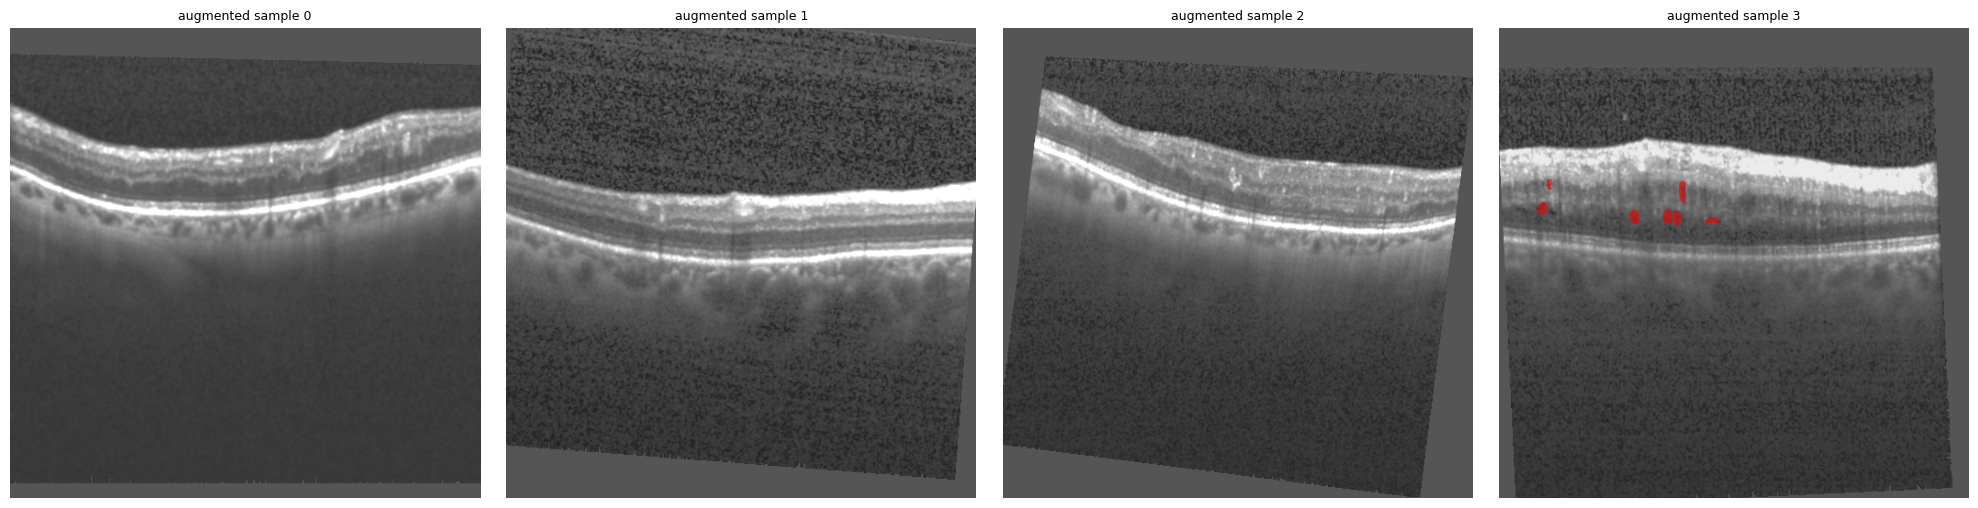

In [ ]:
def augment(img_u8, mask, rng, crop_w=CROP_W):
    H, W = img_u8.shape
    x0 = int(rng.integers(0, W - crop_w + 1))
    img, msk = img_u8[:, x0:x0 + crop_w], mask[:, x0:x0 + crop_w]
    valid = (img > 0).astype(np.uint8)
    f = (img.astype(np.float32) - 1) / 254
    if rng.random() < 0.5:
        f, valid, msk = f[:, ::-1], valid[:, ::-1], msk[:, ::-1]
    if rng.random() < 0.5:
        ang, sc = rng.uniform(-8, 8), rng.uniform(0.9, 1.1)
        M = cv2.getRotationMatrix2D((crop_w / 2, H / 3), ang, sc)
        M[1, 2] += rng.uniform(-30, 30)
        f = cv2.warpAffine(np.ascontiguousarray(f), M, (crop_w, H), flags=cv2.INTER_LINEAR, borderValue=0)
        valid = cv2.warpAffine(np.ascontiguousarray(valid), M, (crop_w, H), flags=cv2.INTER_NEAREST, borderValue=0)
        msk = cv2.warpAffine(np.ascontiguousarray(msk), M, (crop_w, H), flags=cv2.INTER_NEAREST, borderValue=0)
    f = np.ascontiguousarray(f); valid = np.ascontiguousarray(valid).astype(bool); msk = np.ascontiguousarray(msk)
    if rng.random() < 0.5:
        f = np.clip(f, 0, 1) ** rng.uniform(0.7, 1.5)
    if rng.random() < 0.5:
        f = f * rng.uniform(0.8, 1.2) + rng.uniform(-0.1, 0.1)
    if rng.random() < 0.3:
        f = f * rng.gamma(1 / rng.uniform(0.01, 0.06), rng.uniform(0.01, 0.06), f.shape).astype(np.float32)
    if rng.random() < 0.2:
        f = cv2.GaussianBlur(f, (0, 0), rng.uniform(0.5, 1.3))
    if rng.random() < 0.15:   # black wedge at the top or bottom
        yy, xx = np.mgrid[0:H, 0:crop_w]
        h0, h1 = rng.uniform(0, 60, 2)
        line = h0 + (h1 - h0) * xx / crop_w
        wedge = yy < line if rng.random() < 0.5 else yy > H - 1 - line
        valid &= ~wedge
        msk = np.where(wedge, 0, msk)
    f = np.where(valid, np.clip(f, 0, 1.5), 0)
    u8 = np.where(valid, np.clip(np.round(f * 254 + 1), 1, 255), 0).astype(np.uint8)
    return u8, msk

class TrainData(keras.utils.PyDataset):
    def __init__(self, rows, steps, batch, seed=SEED, **kw):
        super().__init__(**kw)
        self.steps, self.batch, self.seed, self.epoch = steps, batch, seed, 0
        self.pools = {True: rows[rows.has_fluid].i.to_numpy(), False: rows[~rows.has_fluid].i.to_numpy()}
    def __len__(self):
        return self.steps
    def on_epoch_end(self):
        self.epoch += 1
    def __getitem__(self, idx):
        rng = np.random.default_rng([self.seed, self.epoch, idx])
        xs, ys = [], []
        for _ in range(self.batch):
            want = bool(rng.random() < FLUID_FRAC)
            pool = self.pools[want] if len(self.pools[want]) else self.pools[not want]
            i = int(rng.choice(pool))
            u8, m = augment(IMAGES[i], MASKS[i], rng)
            xs.append(u8); ys.append(m)
        return normalise(np.stack(xs))[..., None], np.stack(ys).astype(np.int32)

xb, yb = TrainData(TR, 1, BATCH)[0]
fig, axes = plt.subplots(1, BATCH, figsize=(5 * BATCH, 5))
for j in range(BATCH):
    axes[j].imshow(xb[j, ..., 0], cmap="gray", vmin=-2, vmax=4)
    axes[j].imshow(yb[j], cmap=LABEL_CMAP, vmin=-0.5, vmax=3.5, interpolation="nearest")
    axes[j].set_title(f"augmented sample {j}", fontsize=9); axes[j].axis("off")
plt.tight_layout(); plt.show()

# 5. Model (reference attention U-Net), loss, learning-rate schedule

In [ ]:
def conv_block(x, size):
    for _ in range(2):
        x = layers.Conv2D(size, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    return x

def gating_signal(x, out_size):
    x = layers.Conv2D(out_size, 1, padding="same")(x)
    return layers.Activation("relu")(layers.BatchNormalization()(x))

def attention_block(x, gating, inter):
    theta_x = layers.Conv2D(inter, 2, strides=2, padding="same")(x)
    phi_g = layers.Conv2D(inter, 1, padding="same")(gating)
    up_g = layers.Conv2DTranspose(inter, 3, strides=1, padding="same")(phi_g)
    act = layers.Activation("relu")(layers.Add()([up_g, theta_x]))
    psi = layers.Activation("sigmoid")(layers.Conv2D(1, 1, padding="same")(act))
    y = x * layers.UpSampling2D(2)(psi)
    y = layers.Conv2D(x.shape[-1], 1, padding="same")(y)
    return layers.BatchNormalization()(y)

def build_model(f=FILTERS, n_classes=4):
    inp = keras.Input((None, None, 1))
    c1 = conv_block(inp, f)
    c2 = conv_block(layers.MaxPooling2D(2)(c1), 2 * f)
    c3 = conv_block(layers.MaxPooling2D(2)(c2), 4 * f)
    c4 = conv_block(layers.MaxPooling2D(2)(c3), 8 * f)
    x = conv_block(layers.MaxPooling2D(2)(c4), 16 * f)
    for skip, size in [(c4, 8 * f), (c3, 4 * f), (c2, 2 * f), (c1, 2 * f)]:
        att = attention_block(skip, gating_signal(x, size), size)
        x = conv_block(layers.Concatenate()([layers.UpSampling2D(2)(x), att]), size)
    out = layers.BatchNormalization()(layers.Conv2D(n_classes, 1)(x))
    out = layers.Activation("softmax", dtype="float32")(out)
    return keras.Model(inp, out, name="reference_attention_unet")

def fluid_dice_loss(y_true, y_pred, smooth=1.0):
    t = tf.one_hot(tf.cast(y_true, tf.int32), 4)
    inter = tf.reduce_sum(t * y_pred, axis=(0, 1, 2))
    den = tf.reduce_sum(t, axis=(0, 1, 2)) + tf.reduce_sum(y_pred, axis=(0, 1, 2))
    return 1 - tf.reduce_mean(((2 * inter + smooth) / (den + smooth))[1:])

def focal_loss(y_true, y_pred, gamma=FOCAL_GAMMA):
    t = tf.one_hot(tf.cast(y_true, tf.int32), 4)
    p = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
    return tf.reduce_mean(tf.reduce_sum(-t * tf.pow(1 - p, gamma) * tf.math.log(p), axis=-1))

def total_loss(y_true, y_pred):
    return fluid_dice_loss(y_true, y_pred) + FOCAL_WEIGHT * focal_loss(y_true, y_pred)

def compile_model(m, total_steps):
    sched = keras.optimizers.schedules.CosineDecay(LR / 100, max(total_steps - WARMUP_STEPS, 1), alpha=LR_MIN / LR,
                                                   warmup_target=LR, warmup_steps=WARMUP_STEPS)
    m.compile(optimizer=keras.optimizers.Adam(sched), loss=total_loss, jit_compile=JIT)
    return m

print(f"{build_model().count_params()/1e6:.2f} M parameters")
keras.backend.clear_session()

9.44 M parameters


# 6. Prediction, metrics and best-epoch score
Best-epoch score per fluid type *c* (on the validation B-scans): Dice on the B-scans that contain *c*, minus `FA_WEIGHT` × false-alarm share
(pixels predicted as *c* on B-scans without *c* / (those pixels + reference *c* pixels)); averaged over IRF / SRF / PED.

In [ ]:
def predict_labels(model, imgs_u8, batch=8):
    out = np.zeros(imgs_u8.shape, np.uint8)
    for s in range(0, len(imgs_u8), batch):
        chunk = imgs_u8[s:s + batch]; n = len(chunk)
        x = normalise(chunk)[..., None]
        if n < batch:   # fixed batch shape avoids re-compiling
            x = np.concatenate([x, np.zeros((batch - n,) + x.shape[1:], x.dtype)])
        lab = np.asarray(model.predict_on_batch(x))[:n].argmax(-1).astype(np.uint8)
        lab[chunk == 0] = 0
        out[s:s + n] = lab
    return out

def counts(pred, gt):
    # per-B-scan tp / fp / fn for each class
    d = {}
    for c, n in CLASS_NAMES.items():
        pc, gc = pred == c, gt == c
        d[f"tp_{n}"], d[f"fp_{n}"], d[f"fn_{n}"] = (pc & gc).sum((1, 2)), (pc & ~gc).sum((1, 2)), (~pc & gc).sum((1, 2))
    return pd.DataFrame(d)

def val_score(cnt):
    out, scores = {}, []
    for n in NAMES:
        tp, fp, fn = (cnt[f"{a}_{n}"].to_numpy() for a in ("tp", "fp", "fn"))
        pos = (tp + fn) > 0
        fa = fp[~pos].sum()
        out[f"val_fa_{n}"] = float(fa / max(fa + tp[pos].sum() + fn[pos].sum(), 1))
        out[f"val_dice_{n}"] = float(2 * tp[pos].sum() / max(2 * tp[pos].sum() + fp[pos].sum() + fn[pos].sum(), 1)) if pos.any() else np.nan
        if pos.any():
            scores.append(out[f"val_dice_{n}"] - FA_WEIGHT * out[f"val_fa_{n}"])
    out["val_score"] = float(np.mean(scores)) if scores else 0.0
    return out

class ValScore(keras.callbacks.Callback):
    def __init__(self, ids):
        super().__init__(); self.ids = ids
    def on_epoch_end(self, epoch, logs=None):
        res = val_score(counts(predict_labels(self.model, IMAGES[self.ids]), MASKS[self.ids]))
        logs.update(res)
        print(" — val " + "  ".join(f"{n}: Dice {res[f'val_dice_{n}']:.3f} FA {res[f'val_fa_{n}']:.3f}" for n in NAMES)
              + f"  | score {res['val_score']:.3f}")

def case_metrics(cnt, idx):
    # per volume: pixel counts, Dice per class (only if the volume contains it) and volumes in mm³
    d = pd.concat([idx.reset_index(drop=True)[["case", "px_area_mm2", "sz_mm"]], cnt.reset_index(drop=True)], axis=1)
    rows = []
    for case, g in d.groupby("case"):
        row, unit = dict(case=case), (g.px_area_mm2 * g.sz_mm).to_numpy()
        for n in NAMES:
            tp, fp, fn = (int(g[f"{a}_{n}"].sum()) for a in ("tp", "fp", "fn"))
            row.update({f"tp_{n}": tp, f"fp_{n}": fp, f"fn_{n}": fn})
            row[f"dice_{n}"] = 2 * tp / (2 * tp + fp + fn) if tp + fn else np.nan
            row[f"ref_mm3_{n}"] = float(((g[f"tp_{n}"] + g[f"fn_{n}"]) * unit).sum())
            row[f"pred_mm3_{n}"] = float(((g[f"tp_{n}"] + g[f"fp_{n}"]) * unit).sum())
        rows.append(row)
    return pd.DataFrame(rows)

def summary_table(pc):
    rows = []
    for n in NAMES:
        tp, fp, fn = pc[f"tp_{n}"].sum(), pc[f"fp_{n}"].sum(), pc[f"fn_{n}"].sum()
        neg = pc[f"ref_mm3_{n}"] == 0
        rows.append({"class": n, "volumes with": int((~neg).sum()), "Dice/volume (mean)": pc[f"dice_{n}"].mean(),
                     "Dice pooled": 2 * tp / max(2 * tp + fp + fn, 1),
                     "Precision": tp / max(tp + fp, 1), "Recall": tp / max(tp + fn, 1),
                     "false alarms (>200 px) on volumes without": f"{int((pc.loc[neg, f'fp_{n}'] > 200).sum())}/{int(neg.sum())}",
                     "median |vol err| mm³": (pc[f"pred_mm3_{n}"] - pc[f"ref_mm3_{n}"]).abs().median()})
    t = pd.DataFrame(rows).set_index("class")
    t.loc["mean", ["Dice/volume (mean)", "Dice pooled"]] = t[["Dice/volume (mean)", "Dice pooled"]].mean()
    return t

# 7. Train (resumable)

Epoch 1/35
 — val IRF: Dice 0.228 FA 0.857  SRF: Dice 0.621 FA 0.539  PED: Dice 0.159 FA 0.304  | score -0.231

Epoch 1: val_score improved from None to -0.23064, saving model to /content/drive/MyDrive/OCT_Fluid_Models/spectralis_refattn_bscanval/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/OCT_Fluid_Models/spectralis_refattn_bscanval/best_model.keras
400/400 - 548s - 1s/step - loss: 1.7227 - val_fa_IRF: 0.8575 - val_dice_IRF: 0.2278 - val_fa_SRF: 0.5387 - val_dice_SRF: 0.6207 - val_fa_PED: 0.3035 - val_dice_PED: 0.1592 - val_score: -2.3064e-01
Epoch 2/35
 — val IRF: Dice 0.645 FA 0.135  SRF: Dice 0.872 FA 0.009  PED: Dice 0.210 FA 0.090  | score 0.498

Epoch 2: val_score improved from -0.23064 to 0.49762, saving model to /content/drive/MyDrive/OCT_Fluid_Models/spectralis_refattn_bscanval/best_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/OCT_Fluid_Models/spectralis_refattn_bscanval/best_model.keras
400/400 - 505s - 1s/step - loss: 

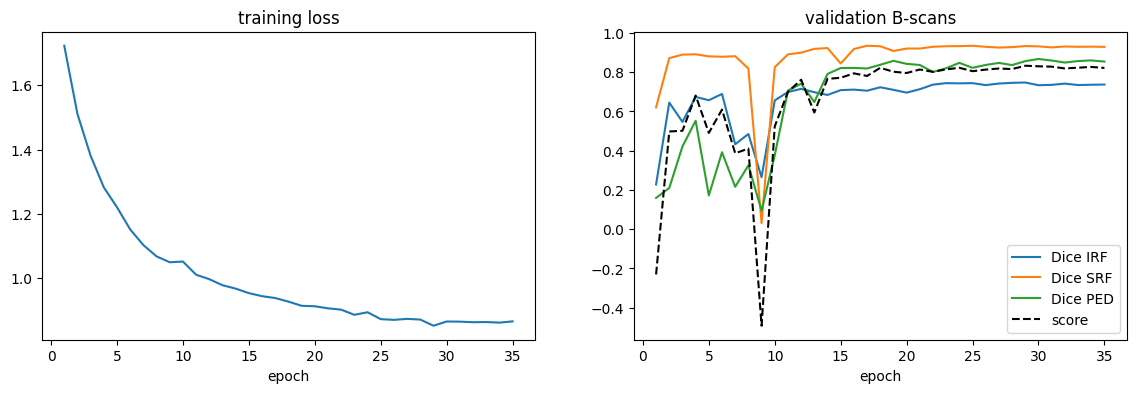

In [ ]:
best_path, hist_path, backup = (os.path.join(SAVE_DIR, x) for x in ("best_model.keras", "history.csv", "backup"))
done_path = os.path.join(SAVE_DIR, "trained.json")

if not os.path.exists(done_path):
    resuming = os.path.isdir(backup) and os.path.exists(hist_path) and os.path.exists(best_path)
    if not resuming:
        for p in (hist_path, best_path):
            if os.path.exists(p): os.remove(p)
        shutil.rmtree(backup, ignore_errors=True)
    best_so_far = float(pd.read_csv(hist_path).val_score.max()) if resuming else None
    if resuming:
        print(f"Resuming after epoch {len(pd.read_csv(hist_path))} (best score so far {best_so_far:.3f})")
    t0 = time.time()
    keras.backend.clear_session()
    model = compile_model(build_model(), EPOCHS * STEPS_PER_EPOCH)
    model.fit(TrainData(TR, STEPS_PER_EPOCH, BATCH, workers=4, use_multiprocessing=False), epochs=EPOCHS, verbose=2,
              callbacks=[ValScore(VA.i.values),
                         keras.callbacks.ModelCheckpoint(best_path, monitor="val_score", mode="max", save_best_only=True,
                                                         verbose=1, initial_value_threshold=best_so_far),
                         keras.callbacks.EarlyStopping(monitor="val_score", mode="max", patience=EARLY_STOP_PATIENCE, verbose=1),
                         keras.callbacks.CSVLogger(hist_path, append=resuming),
                         keras.callbacks.BackupAndRestore(backup)])
    h = pd.read_csv(hist_path)
    json.dump(dict(epochs=len(h), best_epoch=int(h.val_score.idxmax()) + 1, best_val_score=float(h.val_score.max()),
                   train_min=round((time.time() - t0) / 60, 1)), open(done_path, "w"))
    shutil.rmtree(backup, ignore_errors=True)
    del model; keras.backend.clear_session()

print("Training:", json.load(open(done_path)))
MODEL = keras.models.load_model(best_path, compile=False)

h = pd.read_csv(hist_path)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(h.epoch + 1, h.loss); ax[0].set(title="training loss", xlabel="epoch")
for n in NAMES:
    ax[1].plot(h.epoch + 1, h[f"val_dice_{n}"], label=f"Dice {n}")
ax[1].plot(h.epoch + 1, h.val_score, "k--", label="score"); ax[1].set(title="validation B-scans", xlabel="epoch"); ax[1].legend()
plt.show()

# 8. Test on the Spectralis Test set
Each test volume is preprocessed exactly like the training data and predicted on the full canvas. If `reference.mhd` exists in the case
folder, Dice etc. are computed; predicted fluid volumes (mm³) are always reported.

TEST015: IRF/SRF/PED = 0.717 / 0.004 / 1.688 mm³ (5s)
TEST016: IRF/SRF/PED = 0.197 / 0.263 / 2.257 mm³ (11s)
TEST017: IRF/SRF/PED = 0.028 / 0.000 / 0.088 mm³ (16s)
TEST018: IRF/SRF/PED = 0.825 / 0.000 / 0.002 mm³ (22s)
TEST019: IRF/SRF/PED = 1.395 / 0.240 / 0.002 mm³ (27s)
TEST020: IRF/SRF/PED = 0.720 / 0.086 / 0.017 mm³ (32s)
TEST021: IRF/SRF/PED = 0.902 / 0.292 / 0.064 mm³ (38s)
TEST022: IRF/SRF/PED = 0.048 / 0.026 / 0.023 mm³ (43s)
TEST023: IRF/SRF/PED = 0.615 / 0.083 / 0.663 mm³ (48s)
TEST024: IRF/SRF/PED = 0.001 / 0.667 / 1.792 mm³ (54s)
TEST025: IRF/SRF/PED = 0.256 / 0.151 / 0.130 mm³ (59s)
TEST026: IRF/SRF/PED = 0.000 / 0.052 / 0.935 mm³ (64s)
TEST027: IRF/SRF/PED = 0.095 / 0.014 / 0.647 mm³ (70s)
TEST028: IRF/SRF/PED = 0.222 / 0.001 / 0.068 mm³ (75s)

No reference.mhd in the Test folders: only predicted volumes are reported (test_predicted_volumes.csv).
     test predicted, median mm³  train reference, median mm³
IRF                       0.239                        0.227
SRF 

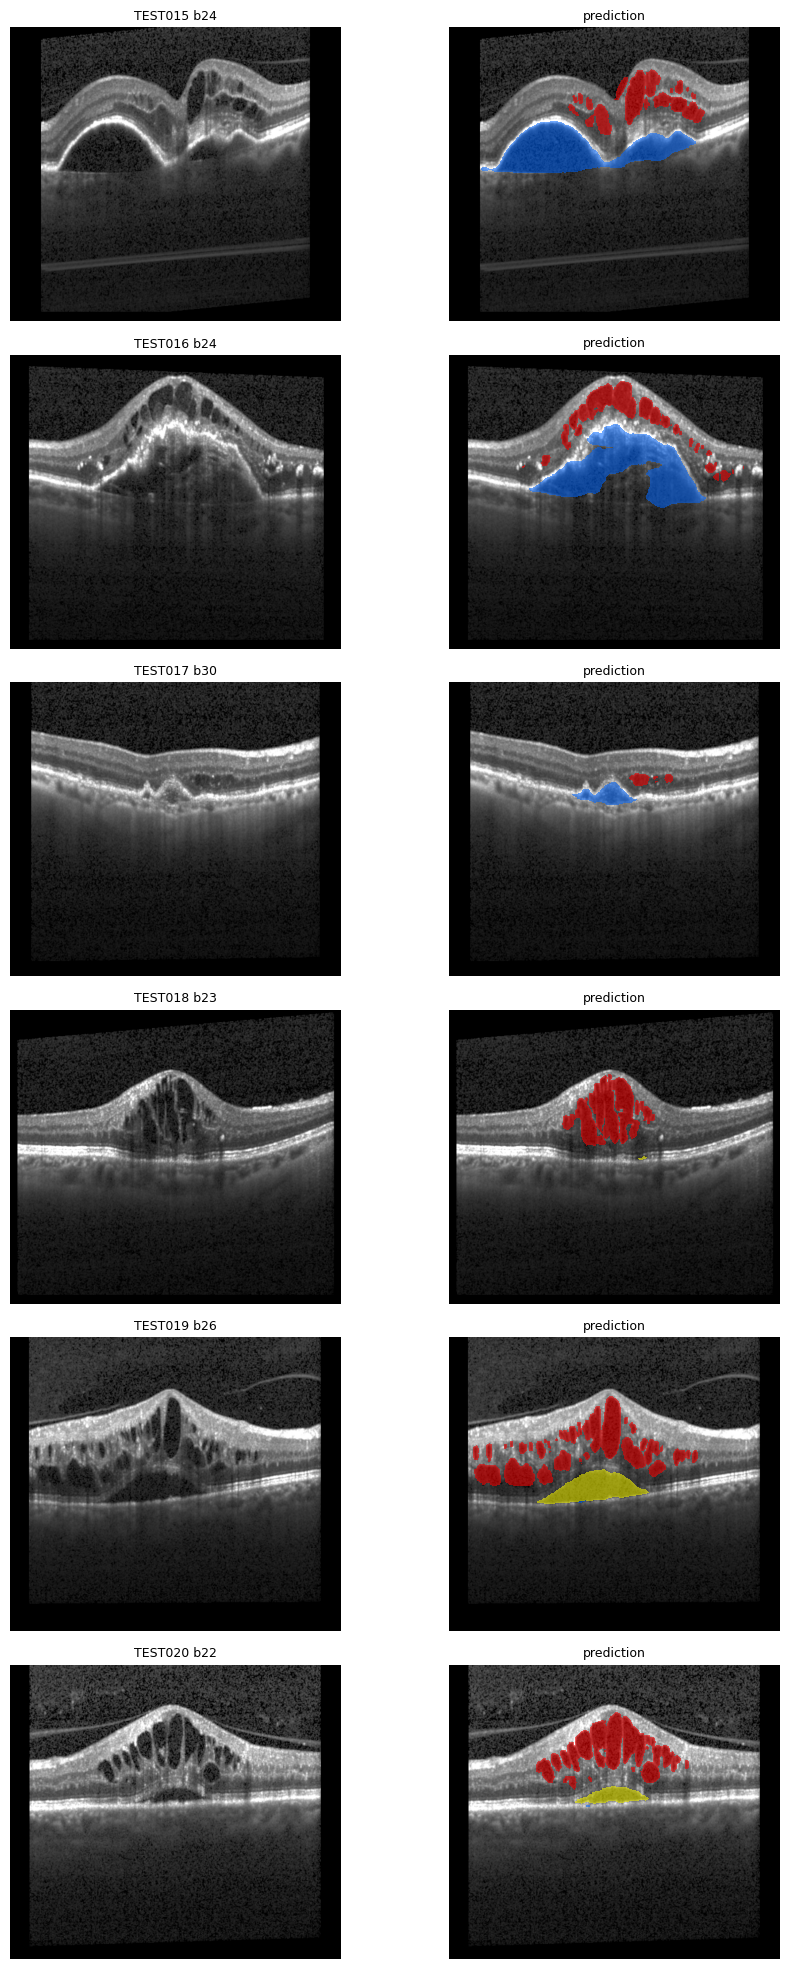

Saved to /content/drive/MyDrive/OCT_Fluid_Models/spectralis_refattn_bscanval : ['best_model.keras', 'history.csv', 'inference_config.json', 'test_predicted_volumes.csv', 'trained.json', 'val_split.json']


In [ ]:
def segment_volume(model, mhd_path):
    # reusable for inference: labels on the canvas (0 bg, 1 IRF, 2 SRF, 3 PED), per-B-scan info, canvases, spacing, volume shape
    vol, sp = read_mhd(mhd_path)
    prep = [prepare_bscan(vol[z], sp[:2]) for z in range(vol.shape[0])]
    canv, infos = np.stack([p[0] for p in prep]), [p[2] for p in prep]
    return predict_labels(model, canv), infos, canv, sp, vol.shape

def write_mhd(path, vol_u8, spacing):
    raw = os.path.basename(path)[:-4] + ".raw"
    vol_u8.astype(np.uint8).tofile(os.path.join(os.path.dirname(path), raw))
    Z, H, W = vol_u8.shape
    with open(path, "w") as fh:
        fh.write(f"ObjectType = Image\nNDims = 3\nBinaryData = True\nBinaryDataByteOrderMSB = False\nCompressedData = False\n"
                 f"DimSize = {W} {H} {Z}\nElementSpacing = {' '.join(str(s) for s in spacing)}\nElementType = MET_UCHAR\n"
                 f"ElementDataFile = {raw}\n")

test_rows, test_pc, vis, t0 = [], [], [], time.time()
for case in list_cases(TEST_DIR):
    pred, infos, canv, sp, shape = segment_volume(MODEL, os.path.join(TEST_DIR, case, "oct.mhd"))
    area = np.array([i["eff_x_mm"] * i["eff_y_mm"] for i in infos])
    row = dict(case=case, bscans=len(pred))
    for c, n in CLASS_NAMES.items():
        px = (pred == c).sum(axis=(1, 2))
        row[f"pred_mm3_{n}"] = float((px * area).sum() * sp[2])
        row[f"pred_bscan_frac_{n}"] = float((px > 0).mean())
    test_rows.append(row)

    gt = None
    ref_path = os.path.join(TEST_DIR, case, "reference.mhd")
    if os.path.exists(ref_path):
        ref, _ = read_mhd(ref_path)
        gt = np.stack([mask_to_canvas(ref[z], sp[:2]) for z in range(len(ref))])
        gt[canv == 0] = 0   # padding is never fluid (as in prediction)
        test_pc.append(case_metrics(counts(pred, gt), pd.DataFrame(dict(case=case, px_area_mm2=area, sz_mm=sp[2]))))
    if SAVE_TEST_MASKS:
        odir = os.path.join(SAVE_DIR, "test_masks", case); os.makedirs(odir, exist_ok=True)
        write_mhd(os.path.join(odir, "prediction.mhd"),
                  np.stack([canvas_to_original(pred[z], infos[z], shape[1], shape[2]) for z in range(len(pred))]), sp)
    if len(vis) < 6:
        z = int((pred > 0).sum(axis=(1, 2)).argmax())
        vis.append((canv[z], pred[z], None if gt is None else gt[z], f"{case} b{z}"))
    print(f"{case}: IRF/SRF/PED = {row['pred_mm3_IRF']:.3f} / {row['pred_mm3_SRF']:.3f} / {row['pred_mm3_PED']:.3f} mm³ "
          f"({time.time()-t0:.0f}s)")

TEST_PRED = pd.DataFrame(test_rows)
TEST_PRED.to_csv(os.path.join(SAVE_DIR, "test_predicted_volumes.csv"), index=False)
if test_pc:
    TEST_PC = pd.concat(test_pc, ignore_index=True)
    TEST_PC.to_csv(os.path.join(SAVE_DIR, "test_per_case.csv"), index=False)
    TEST_TABLE = summary_table(TEST_PC)
    TEST_TABLE.to_csv(os.path.join(SAVE_DIR, "test_results.csv"))
    print(f"\nSpectralis Test set ({len(TEST_PC)} volumes with reference):")
    with pd.option_context("display.float_format", "{:.3f}".format):
        print(TEST_TABLE.to_string())
        print(TEST_PC[["case"] + [f"dice_{n}" for n in NAMES]].to_string(index=False))
else:
    print("\nNo reference.mhd in the Test folders: only predicted volumes are reported (test_predicted_volumes.csv).")
    tr_mm3 = INDEX.assign(**{n: INDEX[f"n_{n}"] * INDEX.px_area_mm2 * INDEX.sz_mm for n in NAMES}).groupby("case")[NAMES].sum()
    print(pd.DataFrame({"test predicted, median mm³": [TEST_PRED[f"pred_mm3_{n}"].median() for n in NAMES],
                        "train reference, median mm³": [tr_mm3[n].median() for n in NAMES]}, index=NAMES).round(3).to_string())

cols = 3 if any(v[2] is not None for v in vis) else 2
fig, axes = plt.subplots(len(vis), cols, figsize=(5 * cols, 3.3 * len(vis)), squeeze=False)
for r, (im, p, g, lab) in enumerate(vis):
    show(axes[r, 0], im, None, lab); show(axes[r, 1], im, p, "prediction")
    if cols == 3:
        show(axes[r, 2], im, g, "reference")
plt.tight_layout(); plt.show()
print("Saved to", SAVE_DIR, ":", sorted(os.listdir(SAVE_DIR)))

# Inference later
Run the imports, config and section 1 cells (and the `predict_labels` / `segment_volume` definitions), then:
```python
MODEL = keras.models.load_model(f"{SAVE_DIR}/best_model.keras", compile=False)
pred, infos, canv, sp, shape = segment_volume(MODEL, "/path/to/oct.mhd")          # labels 0 bg, 1 IRF, 2 SRF, 3 PED
orig = np.stack([canvas_to_original(pred[z], infos[z], shape[1], shape[2]) for z in range(len(pred))])   # original grid
```